# OlhoLimpo: dados, treinamento e avaliação

Este caderno consulta os artefatos preservados da execução. Não repete o treinamento nem altera os conjuntos. As saídas só são preenchidas quando as células são executadas. O README contém os comandos para refazer o pipeline completo.

In [1]:
from pathlib import Path
import csv
import json
import hashlib

root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
metrics_path = root / 'reports/metrics.json'
if not metrics_path.is_file():
    raise FileNotFoundError('Execute a avaliação antes deste caderno.')
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
print('Artefato:', metrics_path.relative_to(root))
print('SHA-256:', hashlib.sha256(metrics_path.read_bytes()).hexdigest())

Artefato: reports\metrics.json
SHA-256: 544a3f487d67f86e58b50aa25891e1de9c7e9cd4e54349cdf8374806c6bade4f


## Dados e divisão

A classe agregada é `residuo`. As contagens devem corresponder aos manifestos efetivamente usados, sem contar aumentos como novas imagens independentes. A separação garante arquivos distintos e grupos encontrados por dHash; não comprova independência de cenas ou objetos físicos. Os 778 grupos possuem uma imagem cada e os metadados são incompletos.

In [2]:
print(json.dumps(metrics.get('dataset', {}), indent=2, ensure_ascii=False))
manifest_dir = root / 'data/manifests'
print('Manifestos:', [p.name for p in sorted(manifest_dir.glob('*')) if p.is_file()])

{
  "train_images": 544,
  "train_instances": 1854,
  "val_images": 117,
  "val_instances": 345,
  "test_images": 117,
  "test_instances": 395,
  "annotation_sha256": "812c2e3f0d336b437f276597715de2abb08bb8a641599c45f593d233ec66457b",
  "source": "TACO",
  "independent_negatives": 0,
  "note": "Sem ensaio local independente ou coleta própria nesta execução."
}
Manifestos: ['class_mapping.json', 'download_failures.json', 'excluded.json', 'summary.json', 'taco.json']


## Treinamento customizado

Configuração e identificação do checkpoint. A leitura dos registros não significa que o treino foi executado por este notebook.

In [3]:
print(json.dumps(metrics.get('training', {}), indent=2, ensure_ascii=False))
print(json.dumps(metrics.get('model', {}), indent=2, ensure_ascii=False))

{
  "base_model": "yolo26n.pt",
  "epochs_requested": 60,
  "epochs_completed": 60,
  "batch": 16,
  "imgsz": 640,
  "seed": 42,
  "duration_seconds": 1136.87,
  "gpu": "NVIDIA GeForce RTX 3060",
  "torch": "2.14.1+cu130",
  "ultralytics": "8.4.211",
  "results_csv": "reports/training/results.csv"
}
{
  "name": "YOLO26n — residuo",
  "sha256": "d503b3a8df846827b67c6717edde10958e70e34f58c5ac64d5c0e8e3c85ac9ec",
  "weights": "models/best.pt"
}


In [4]:
declared_log = metrics.get('training', {}).get('results_csv')
candidates = [root / declared_log] if declared_log else (sorted((root / 'runs').rglob('results.csv')) if (root / 'runs').exists() else [])
if len(candidates) == 1 and candidates[0].is_file():
    log_path = candidates[0]
    with log_path.open(encoding='utf-8-sig', newline='') as stream:
        history = [{key.strip(): value for key, value in row.items()} for row in csv.DictReader(stream)]
    print('Log consultado:', log_path.relative_to(root))
    print('Épocas registradas:', len(history))
    print('Última linha:', history[-1] if history else {})
else:
    print('Defina training.results_csv nas métricas para identificar o log desta execução. Não foi escolhido um treino arbitrariamente.')
    print('Arquivos encontrados:', [str(p.relative_to(root)) for p in candidates])

Log consultado: reports\training\results.csv
Épocas registradas: 60
Última linha: {'epoch': '60', 'time': '1110.21', 'train/box_loss': '1.27294', 'train/cls_loss': '0.90141', 'train/l1_loss': '0.00502', 'metrics/precision(B)': '0.69273', 'metrics/recall(B)': '0.43768', 'metrics/mAP50(B)': '0.45953', 'metrics/mAP50-95(B)': '0.29991', 'val/box_loss': '1.6815', 'val/cls_loss': '2.07628', 'val/l1_loss': '0.00795', 'lr/pg0': '5.3e-05', 'lr/pg1': '5.3e-05', 'lr/pg2': '5.3e-05'}


## Avaliação reservada

Precisão, recall e AP pertencem ao protocolo indicado nas métricas. O teste não deve orientar escolha de checkpoint ou limiar. Confiança não é probabilidade calibrada.

In [5]:
print(json.dumps(metrics['evaluation'], indent=2, ensure_ascii=False))
print(json.dumps(metrics.get('benchmark', {}), indent=2, ensure_ascii=False))

{
  "precision": 0.5423076923076923,
  "recall": 0.3569620253164557,
  "f1": 0.4305343511450382,
  "true_positives": 141,
  "false_positives": 119,
  "false_negatives": 254,
  "map50": 0.38516873626078185,
  "map50_95": 0.24995961410824616,
  "confidence": 0.35,
  "iou": 0.5,
  "selection_split": "val",
  "evaluation_split": "test",
  "ap_note": "AP integrada pela Ultralytics; precisão/recall/F1 em limiar fixo, com pareamento por confiança e IoU 0,50."
}
{
  "device": "0",
  "imgsz": 640,
  "images": 30,
  "warmup": "modelo aquecido antes da medição",
  "p50_ms": 18.72074999846518,
  "p95_ms": 25.37271999754011,
  "fps": 51.38190784850606,
  "scope": "Inferência + anotação em imagens pré-decodificadas; sem captura/exibição."
}


## Evidências visuais e erros

Exemplos de acertos e falhas devem manter sua identificação de origem. Cenas controladas não substituem teste em campo.

000103.jpg: verde = predição; azul = anotação. Imagem do teste interno TACO.


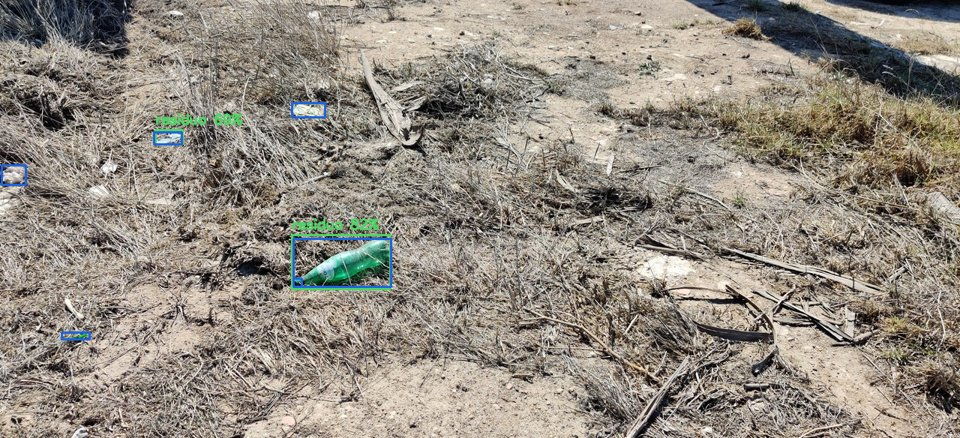

000104.jpg: verde = predição; azul = anotação. Imagem do teste interno TACO.


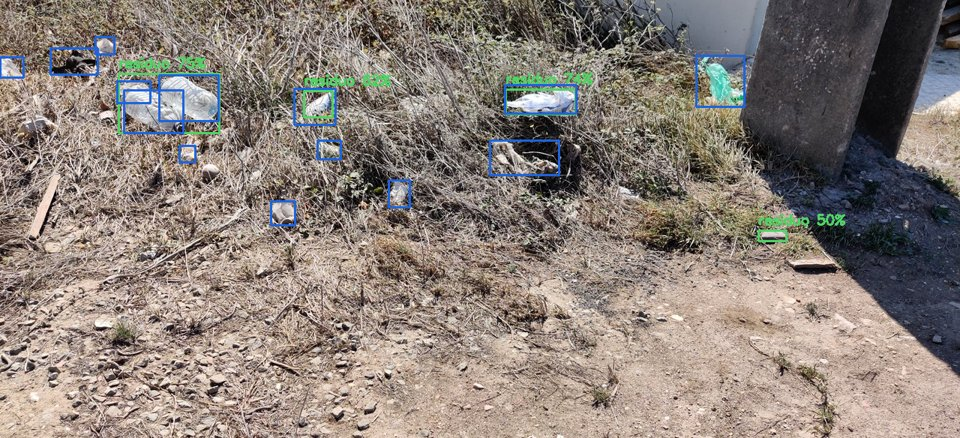

Treinamento e validação: BoxPR_curve.png. Não são métricas do teste reservado.


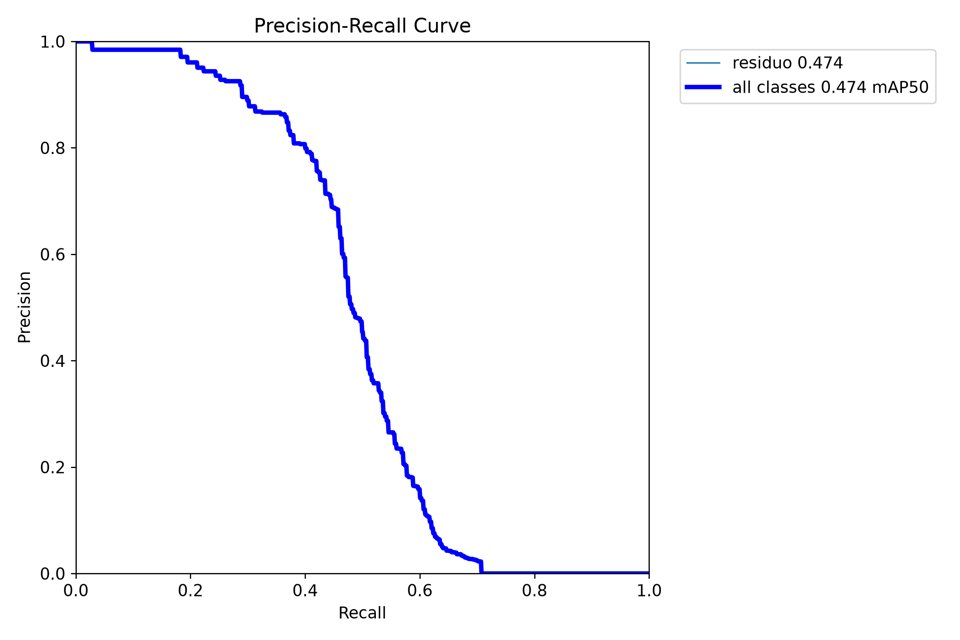

Pré-visualizações reduzidas; evidências completas preservadas nos arquivos de origem e no PDF.
[
  {
    "image": "000103.jpg",
    "true_positives": 2,
    "false_positives": 0,
    "false_negatives": 4,
    "description": "0 falso(s) positivo(s) e 4 falso(s) negativo(s) no limiar escolhido pela validação e IoU 0,50.",
    "observation": "A garrafa maior foi localizada. Quatro resíduos anotados, incluindo fragmentos pequenos no fundo seco, ficaram sem correspondência.",
    "hypothesis": "Poucos pixels e baixo contraste podem dificultar a representação dos fragmentos; é uma hipótese visual, não uma explicação causal comprovada.",
    "proposed_correction": "Ampliar exemplos de objetos pequenos no treino e avaliar recortes com preservação de contexto, usando somente a validação para selecionar a mudança."
  },
  {
    "image": "000104.jpg",
    "true_positives": 2,
    "false_positives": 2,
    "false_negatives": 12,
    "description": "2 falso(s) positivo(s) e 12 falso(s) negativo(s) 

In [6]:
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image, display

figures = [{'path': f} if isinstance(f, str) else f for f in metrics.get('figures', [])]
examples = [f for f in figures if 'exemplo-' in f['path']][:2]
curves = [f for f in figures if 'BoxPR_curve' in f['path']][:1]
for item in examples + curves:
    path = root / item['path']
    with PILImage.open(path) as original:
        preview = original.convert('RGB')
        preview.thumbnail((960, 960))
        buffer = BytesIO()
        preview.save(buffer, format='JPEG', quality=85, optimize=True)
    print(item.get('caption', path.name))
    display(Image(data=buffer.getvalue(), format='jpeg', width=760))
print('Pré-visualizações reduzidas; evidências completas preservadas nos arquivos de origem e no PDF.')
print(json.dumps(metrics.get('errors', []), indent=2, ensure_ascii=False))

## Interpretação

Conferir objetos pequenos, oclusão e fundos carregados. Uma embalagem em uso pode ter aparência igual à de uma descartada. Ausência de caixa não comprova que o ambiente esteja limpo. Contagens por quadro não equivalem a objetos físicos únicos. Novas melhorias exigem uma validação independente quando o teste anterior já tiver orientado decisões.